# Clustering de noticias del mundo con 5 algoritmos
**Flujo:** noticias reales por área (RSS) → texto limpio → **texto convertido en números** → Jerárquico · K-Means · DBSCAN · HDBSCAN · OPTICS → comparación contra el **área real** de cada noticia.

### ¿Cómo "entrenan" los modelos con texto?
Los algoritmos de clustering **no leen palabras**: solo entienden números. Por eso hay dos pasos:

1. **Representación del texto** (convertir cada noticia en un vector):
   - **TF-IDF + LSA**: cada noticia se describe por las palabras que la distinguen (TF-IDF) y luego se comprimen a ~60 "temas latentes" (LSA/SVD).
   - **Embeddings** (opcional): un modelo de lenguaje preentrenado convierte cada noticia en un vector que captura su *significado* (sinónimos, contexto, idiomas).
2. **Clustering (aprendizaje no supervisado)**: los modelos **no ven el área**; solo agrupan noticias cuyos vectores están cerca.

### ¿Cómo se diferencian los modelos aquí?
Como cada noticia viene de una sección conocida (Mundo, Economía, Tecnología, Ciencia, Deportes, Cultura), podemos usar **métricas externas** (ARI, NMI, V-measure, pureza) que miden si los grupos reproducen las áreas reales, además de las **métricas internas** (Silhouette, Calinski-Harabasz, Davies-Bouldin), la **estabilidad** y la **cobertura**.
> Importante: los hiperparámetros (`eps`, `min_cluster_size`, `xi`) se eligen **solo con métricas internas**, sin mirar el área. El área real se usa únicamente para evaluar.

## 0) Configuración

In [1]:
# ---------------------------------------------------------
# 0) Configuración
# ---------------------------------------------------------
import os, re, html, sys, subprocess, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
warnings.filterwarnings("ignore")

def _pip(*paquetes):
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *paquetes], check=True)
try:
    import feedparser
except ImportError:
    _pip("feedparser"); import feedparser
import requests

# ---------------- Parámetros que puedes ajustar ----------------
IDIOMA          = "en"    # "en" = BBC + Guardian + NYT (recomendado, 3 fuentes por área) | "es" = El País (experimental)
N_POR_AREA      = 25      # noticias por área (6 áreas x 25 = 150 noticias). Mínimo pedido: 50 en total
MIN_NOTICIAS    = 50      # si se recolectan menos, se detiene
REUSAR_CSV      = False   # True = reutiliza noticias_dataset.csv guardado (para repetir EXACTAMENTE el mismo experimento)
RUTA_CSV_MANUAL = None    # o pon la ruta a tu propio CSV con columnas: titulo, resumen (opcional), area

N_SVD           = 60      # dimensiones de LSA (temas latentes)
USAR_EMBEDDINGS = True    # True = además de TF-IDF/LSA usa embeddings de un modelo de lenguaje (descarga ~120 MB)
MODELO_EMB      = "paraphrase-multilingual-MiniLM-L12-v2"
K_TEXTO         = None    # None = nº de áreas reales (jerárquico y K-Means). O pon un número
MIN_SAMPLES     = 4       # DBSCAN y OPTICS: vecinos mínimos
MAX_RUIDO       = 0.40    # máximo de noticias "ruido" aceptado al elegir parámetros automáticamente
N_BOOT          = 10      # remuestreos (80 %) para medir estabilidad
SEMILLA         = 42
USAR_DRIVE      = True    # guarda resultados en Google Drive (si no estás en Colab, usa carpeta local)

BASE = "./ANALISIS_NOTICIAS"
if USAR_DRIVE:
    try:
        from google.colab import drive
        drive.mount('/content/drive')
        BASE = "/content/drive/MyDrive/ANALISIS_NOTICIAS"
    except Exception:
        print("No estoy en Colab: guardo en", BASE)
RESULTADOS = os.path.join(BASE, "resultados")
os.makedirs(RESULTADOS, exist_ok=True)
def guardar(nombre):
    plt.savefig(os.path.join(RESULTADOS, nombre), dpi=150, bbox_inches="tight")
print("Resultados en:", RESULTADOS)

No estoy en Colab: guardo en ./ANALISIS_NOTICIAS
Resultados en: ./ANALISIS_NOTICIAS/resultados


## 1) Recolectar noticias del mundo, por área
Se leen los **feeds RSS** de varios medios. La sección de cada feed (Mundo, Economía, Tecnología, Ciencia, Deportes, Cultura) es el **área verdadera** de la noticia;
los modelos nunca la ven al agrupar. Se toman noticias de **varios medios por área, alternándolos**, para que los grupos no dependan del estilo de un solo periódico.
Se guarda el resultado en `noticias_dataset.csv` para poder repetir el experimento (los RSS cambian cada día).

In [2]:
FEEDS = {
  "en": {
    "Mundo":      [("BBC", "https://feeds.bbci.co.uk/news/world/rss.xml"),
                   ("Guardian", "https://www.theguardian.com/world/rss"),
                   ("NYT", "https://rss.nytimes.com/services/xml/rss/nyt/World.xml")],
    "Economía":   [("BBC", "https://feeds.bbci.co.uk/news/business/rss.xml"),
                   ("Guardian", "https://www.theguardian.com/business/rss"),
                   ("NYT", "https://rss.nytimes.com/services/xml/rss/nyt/Business.xml")],
    "Tecnología": [("BBC", "https://feeds.bbci.co.uk/news/technology/rss.xml"),
                   ("Guardian", "https://www.theguardian.com/technology/rss"),
                   ("NYT", "https://rss.nytimes.com/services/xml/rss/nyt/Technology.xml")],
    "Ciencia":    [("BBC", "https://feeds.bbci.co.uk/news/science_and_environment/rss.xml"),
                   ("Guardian", "https://www.theguardian.com/science/rss"),
                   ("NYT", "https://rss.nytimes.com/services/xml/rss/nyt/Science.xml")],
    "Deportes":   [("BBC", "https://feeds.bbci.co.uk/sport/rss.xml"),
                   ("Guardian", "https://www.theguardian.com/sport/rss"),
                   ("NYT", "https://rss.nytimes.com/services/xml/rss/nyt/Sports.xml")],
    "Cultura":    [("BBC", "https://feeds.bbci.co.uk/news/entertainment_and_arts/rss.xml"),
                   ("Guardian", "https://www.theguardian.com/culture/rss"),
                   ("NYT", "https://rss.nytimes.com/services/xml/rss/nyt/Arts.xml")],
  },
  "es": {
    "Mundo":      [("El País", "https://feeds.elpais.com/mrss-s/pages/ep/site/elpais.com/section/internacional/portada")],
    "Economía":   [("El País", "https://feeds.elpais.com/mrss-s/pages/ep/site/elpais.com/section/economia/portada")],
    "Tecnología": [("El País", "https://feeds.elpais.com/mrss-s/pages/ep/site/elpais.com/section/tecnologia/portada")],
    "Ciencia":    [("El País", "https://feeds.elpais.com/mrss-s/pages/ep/site/elpais.com/section/ciencia/portada")],
    "Deportes":   [("El País", "https://feeds.elpais.com/mrss-s/pages/ep/site/elpais.com/section/deportes/portada")],
    "Cultura":    [("El País", "https://feeds.elpais.com/mrss-s/pages/ep/site/elpais.com/section/cultura/portada")],
  },
}
UA = {"User-Agent": "Mozilla/5.0 (compatible; ClusteringNoticias/1.0)"}

def _limpiar(t):
    t = html.unescape(re.sub(r"<[^>]+>", " ", t or ""))
    t = re.sub(r"(?i)continue reading\.*|read more\.*|seguir leyendo\.*", " ", t)
    return re.sub(r"\s+", " ", t).strip()

def leer_feed(url):
    try:
        r = requests.get(url, headers=UA, timeout=20); r.raise_for_status()
        return feedparser.parse(r.content).entries
    except Exception as e:
        print(f"  ⚠ no pude leer {url} → {type(e).__name__}")
        return []

def recolectar():
    filas = []
    for area, fuentes in FEEDS[IDIOMA].items():
        pools = []
        for fuente, url in fuentes:
            items = []
            for e in leer_feed(url):
                t = _limpiar(e.get("title", "")); s = _limpiar(e.get("summary", e.get("description", "")))
                if s.lower().startswith(t.lower()):
                    s = s[len(t):].strip(" .:-")
                items.append(dict(area=area, fuente=fuente, titulo=t, resumen=s, fecha=e.get("published", "")))
            pools.append(items)
        vistos, n, i = set(), 0, 0
        while n < N_POR_AREA and any(i < len(p) for p in pools):       # alterna medios para equilibrar
            for p in pools:
                if i < len(p) and n < N_POR_AREA:
                    it = p[i]
                    clave = re.sub(r"\W+", " ", it["titulo"].lower()).strip()
                    if clave and clave not in vistos and len((it["titulo"] + " " + it["resumen"]).split()) >= 6:
                        vistos.add(clave); filas.append(it); n += 1
            i += 1
        print(f"  {area:<11} {n} noticias")
    return pd.DataFrame(filas)

RUTA_DATASET = os.path.join(BASE, "noticias_dataset.csv")
if RUTA_CSV_MANUAL:
    noticias = pd.read_csv(RUTA_CSV_MANUAL); print("Noticias leídas de", RUTA_CSV_MANUAL)
elif REUSAR_CSV and os.path.exists(RUTA_DATASET):
    noticias = pd.read_csv(RUTA_DATASET); print("Noticias reutilizadas de", RUTA_DATASET)
else:
    print("Descargando noticias…")
    noticias = recolectar()
    if len(noticias):
        os.makedirs(BASE, exist_ok=True); noticias.to_csv(RUTA_DATASET, index=False)

for c in ("resumen", "fuente", "fecha"):
    if c not in noticias.columns: noticias[c] = ""
noticias = noticias.fillna("")
noticias["texto"] = (noticias["titulo"] + ". " + noticias["resumen"]).str.strip()
noticias.index = [f"n{i:03d}" for i in range(len(noticias))]
assert len(noticias) >= MIN_NOTICIAS, (f"Solo hay {len(noticias)} noticias (< {MIN_NOTICIAS}). Revisa tu conexión, "
                                       "prueba IDIOMA='en' o sube tu propio CSV con RUTA_CSV_MANUAL.")
areas = sorted(noticias["area"].unique())
y_area = noticias["area"].values
K_TXT = K_TEXTO if K_TEXTO else len(areas)
n_docs = len(noticias)
print(f"\n{n_docs} noticias | {len(areas)} áreas: {areas} | k usado en jerárquico/K-Means: {K_TXT}")

display(pd.crosstab(noticias["area"], noticias["fuente"], margins=True).rename_axis("área"))
for a in areas:
    print(f"\n[{a}]")
    for t in noticias.loc[noticias.area == a, "titulo"].head(3): print("  •", t)

Descargando noticias…
  Mundo       25 noticias
  Economía    25 noticias
  Tecnología  25 noticias
  Ciencia     25 noticias
  Deportes    25 noticias
  Cultura     25 noticias

150 noticias | 6 áreas: ['Ciencia', 'Cultura', 'Deportes', 'Economía', 'Mundo', 'Tecnología'] | k usado en jerárquico/K-Means: 6


fuente,BBC,Guardian,NYT,All
área,,,,
Ciencia,9,8,8,25
Cultura,9,8,8,25
Deportes,13,12,0,25
Economía,9,9,7,25
Mundo,9,8,8,25
Tecnología,9,8,8,25
All,58,53,39,150



[Ciencia]
  • Building boom puts 300,000 people in the path of potential Himalayan disasters
  • How rising seas transformed dry land into Venice lagoon
  • After Flying Past the Moon, an Artemis II Astronaut Lands in California

[Cultura]
  • Family row over George Michael items up for auction - including Faith guitar
  • ‘We sold out tickets within 13 minutes’: new novel from romantasy author Sarah J Maas sparks fan mania
  • How a Walmart Heir Is Transforming Rural Arkansas Into a Design Powerhouse

[Deportes]
  • 'He could be happier' - why is Estevao becoming Chelsea's forgotten man?
  • Milwaukee Brewers close out Tampa Bay Rays to end 57-year wait for first World Series title
  • Fleetwood to face Everton or Newcastle in last eight

[Economía]
  • I earn £30,000. I'm angry there was no fuel duty cut in the Budget
  • Fed holds interest rates steady in last decision before midterms
  • CNN, MS Now and Politico Update Lawsuit Against Trump Over White House Access

[Mundo]
  • Hig

## 2) Del texto a números (cómo "ve" el texto cada modelo)
**TF-IDF** da más peso a las palabras frecuentes en una noticia pero raras en el resto (p. ej. *striker*, *inflation*, *quantum*).
**LSA (SVD)** comprime miles de palabras a ~60 ejes de "tema" y se **normaliza** (longitud 1), de modo que la distancia euclidiana equivale a la distancia coseno, la adecuada para texto.
Los **embeddings** son vectores de un modelo de lenguaje preentrenado: noticias con significado parecido quedan cerca aunque no compartan palabras.

In [3]:
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import Normalizer

STOP_ES = {"de","la","que","el","en","y","a","los","del","se","las","por","un","para","con","no","una","su","al","lo","como","más","pero",
           "sus","le","ya","o","este","sí","porque","esta","entre","cuando","muy","sin","sobre","también","me","hasta","hay","donde","quien",
           "desde","todo","nos","durante","todos","uno","les","ni","contra","otros","ese","eso","ante","ellos","e","esto","antes","algunos",
           "qué","unos","yo","otro","otras","otra","él","tanto","esa","estos","mucho","quienes","nada","muchos","cual","sea","poco","ella",
           "estar","haber","estas","algo","nosotros","es","son","ha","han","fue","ser","tras","según","más","años","año"}
STOP = list(ENGLISH_STOP_WORDS | STOP_ES | {"bbc","guardian","nytimes","said","says","say","continue","reading"})

tfidf = TfidfVectorizer(stop_words=STOP, ngram_range=(1, 2), min_df=2, max_df=0.5,
                        sublinear_tf=True, strip_accents="unicode")
X_tfidf = tfidf.fit_transform(noticias["texto"])
vocab = np.array(tfidf.get_feature_names_out())
n_svd = max(2, min(N_SVD, X_tfidf.shape[1] - 1, n_docs - 1))
svd = TruncatedSVD(n_components=n_svd, random_state=SEMILLA)
X_lsa = Normalizer().fit_transform(svd.fit_transform(X_tfidf))
print(f"Vocabulario TF-IDF: {len(vocab)} términos | LSA: {n_svd} dimensiones "
      f"({svd.explained_variance_ratio_.sum():.1%} de la varianza)")

# Ejemplo: ¿qué palabras describen a una noticia de cada área?
for a in areas[:3]:
    i = np.where(y_area == a)[0][0]
    fila = X_tfidf[i].toarray().ravel()
    print(f"\n[{a}] {noticias.titulo.iloc[i][:90]}")
    print("   palabras clave (TF-IDF):", ", ".join(vocab[np.argsort(fila)[::-1][:6]]))

REPRESENTACIONES = {"TF-IDF + LSA": X_lsa}
if USAR_EMBEDDINGS:
    try:
        try:
            from sentence_transformers import SentenceTransformer
        except ImportError:
            _pip("sentence-transformers"); from sentence_transformers import SentenceTransformer
        modelo_emb = SentenceTransformer(MODELO_EMB)
        X_emb = modelo_emb.encode(noticias["texto"].tolist(), normalize_embeddings=True, show_progress_bar=False)
        REPRESENTACIONES["Embeddings"] = np.asarray(X_emb)
        print(f"\nEmbeddings: {X_emb.shape[1]} dimensiones por noticia ({MODELO_EMB})")
    except Exception as e:
        print("⚠ No pude calcular embeddings, sigo solo con TF-IDF + LSA:", type(e).__name__, e)
print("Representaciones disponibles:", list(REPRESENTACIONES))

Vocabulario TF-IDF: 1078 términos | LSA: 60 dimensiones (61.3% de la varianza)

[Ciencia] Building boom puts 300,000 people in the path of potential Himalayan disasters
   palabras clave (TF-IDF): 000 people, tourism, 300, path, parts, housing

[Cultura] Family row over George Michael items up for auction - including Faith guitar
   palabras clave (TF-IDF): singer, wanted, michael, assistant, late, george

[Deportes] 'He could be happier' - why is Estevao becoming Chelsea's forgotten man?
   palabras clave (TF-IDF): chelsea, competition, limited, man, faces, leave


modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/3.89k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/645 [00:00<?, ?B/s]

... (5 outputs left out)

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]


Embeddings: 384 dimensiones por noticia (paraphrase-multilingual-MiniLM-L12-v2)
Representaciones disponibles: ['TF-IDF + LSA', 'Embeddings']


## 3) Los 5 algoritmos y las métricas
- **Jerárquico (Ward)** y **K-Means** reciben `k` (= nº de áreas).
- **DBSCAN, HDBSCAN y OPTICS** no reciben `k`: se barre su parámetro (`eps`, `min_cluster_size`, `xi`) y se elige el de **mejor Silhouette interno** con ruido ≤ `MAX_RUIDO` y entre 2 y `3·k` clusters (evita que se fragmente en decenas de grupos diminutos). **Nunca se usa el área real para elegir.**
- Métricas **externas** (contra el área real; el ruido cuenta como un grupo más, así que penaliza a quien descarta muchas noticias): **ARI, NMI, homogeneidad, completitud, V-measure, pureza**.
- Métricas **internas** (sin contar ruido): Silhouette, Calinski-Harabasz, Davies-Bouldin. Además: **estabilidad** (ARI con remuestreos) y **cobertura**.

In [4]:
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN, OPTICS
try:
    from sklearn.cluster import HDBSCAN
except ImportError:
    _pip("hdbscan"); from hdbscan import HDBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (silhouette_score, calinski_harabasz_score, davies_bouldin_score, adjusted_rand_score,
                             normalized_mutual_info_score, homogeneity_score, completeness_score, v_measure_score)

MAX_CLUSTERS = 3 * K_TXT
ALGS = ["Jerárquico (Ward)", "K-Means", "DBSCAN", "HDBSCAN", "OPTICS"]
COL_ALG = {"Jerárquico (Ward)": "tab:blue", "K-Means": "tab:green", "DBSCAN": "tab:red", "HDBSCAN": "tab:purple", "OPTICS": "tab:orange"}
COL_AREA = {a: plt.cm.tab10(i) for i, a in enumerate(areas)}
PALETA = plt.cm.tab20(np.linspace(0, 1, 20))
def color_cluster(k):  return "lightgray" if k == -1 else PALETA[(2 * k) % 20]
def nombre_cluster(k): return "Ruido" if k == -1 else f"Cluster {k}"

def pureza(y, lab):
    t = pd.crosstab(lab, y)
    return t.max(axis=1).sum() / t.values.sum()

def metricas(X, lab, y):
    m = lab != -1; ncl = len(set(lab[m]))
    out = dict(n_clusters=ncl, ruido_pct=100 * (~m).mean(), cobertura=m.mean(),
               cluster_mayor_pct=100 * pd.Series(lab[m]).value_counts().max() / len(lab) if ncl else np.nan)
    if ncl >= 2 and m.sum() > ncl:
        out.update(silhouette=silhouette_score(X[m], lab[m]), calinski=calinski_harabasz_score(X[m], lab[m]),
                   davies_bouldin=davies_bouldin_score(X[m], lab[m]))
    else:
        out.update(silhouette=np.nan, calinski=np.nan, davies_bouldin=np.nan)
    out.update(ARI=adjusted_rand_score(y, lab), NMI=normalized_mutual_info_score(y, lab),
               homogeneidad=homogeneity_score(y, lab), completitud=completeness_score(y, lab),
               V_measure=v_measure_score(y, lab), pureza=pureza(y, lab))
    return out

def estabilidad(ajustar, X, lab_full, n=N_BOOT, frac=0.8, seed=0):
    rng = np.random.default_rng(seed); aris = []
    for _ in range(n):
        idx = rng.choice(len(X), int(frac * len(X)), replace=False)
        aris.append(adjusted_rand_score(lab_full[idx], ajustar(X[idx])))
    return float(np.mean(aris))

def barrer_y_elegir(X, grid, ajustar, nombre):
    filas = []
    for p in grid:
        lab = ajustar(X, p); m = lab != -1; ncl = len(set(lab[m]))
        sil = silhouette_score(X[m], lab[m]) if ncl >= 2 and m.sum() > ncl else np.nan
        filas.append({nombre: p, "n_clusters": ncl, "ruido": 1 - m.mean(), "silhouette": sil})
    d = pd.DataFrame(filas)
    ok = d[(d.n_clusters >= 2) & (d.n_clusters <= MAX_CLUSTERS) & (d.ruido <= MAX_RUIDO)].dropna(subset=["silhouette"])
    if len(ok):
        return ok.loc[ok.silhouette.idxmax(), nombre], d, "mejor silhouette interno"
    cand = d[d.n_clusters >= 2]
    if len(cand):
        return cand.loc[cand.ruido.idxmin(), nombre], d, "menor ruido con >= 2 clusters (ningún valor cumplió los límites)"
    return d[nombre].iloc[len(d) // 2], d, "valor central (no se hallaron >= 2 clusters)"

def correr(X):
    """Ajusta los 5 algoritmos sobre X. Devuelve etiquetas, parámetros, barridos y ajustadores."""
    kd = np.sort(NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(X).kneighbors(X)[0][:, -1])
    f_db  = lambda X_, p: DBSCAN(eps=p, min_samples=MIN_SAMPLES).fit_predict(X_)
    f_hdb = lambda X_, p: HDBSCAN(min_cluster_size=int(p)).fit_predict(X_)
    f_opt = lambda X_, p: OPTICS(min_samples=MIN_SAMPLES, xi=float(p)).fit_predict(X_)
    eps, d_eps, o1 = barrer_y_elegir(X, np.linspace(np.percentile(kd, 10), kd.max(), 30), f_db, "eps")
    mcs, d_mcs, o2 = barrer_y_elegir(X, list(range(3, max(5, min(25, len(X) // 4)) + 1)), f_hdb, "min_cluster_size")
    xi,  d_xi,  o3 = barrer_y_elegir(X, np.round(np.linspace(0.01, 0.30, 15), 3), f_opt, "xi")
    ajust = {
        "Jerárquico (Ward)": lambda X_: AgglomerativeClustering(n_clusters=K_TXT, linkage="ward").fit_predict(X_),
        "K-Means":           lambda X_: KMeans(n_clusters=K_TXT, n_init=10, random_state=SEMILLA).fit_predict(X_),
        "DBSCAN":            lambda X_: f_db(X_, eps),
        "HDBSCAN":           lambda X_: f_hdb(X_, mcs),
        "OPTICS":            lambda X_: f_opt(X_, xi),
    }
    labs = {a: ajust[a](X) for a in ALGS}
    params = {"Jerárquico (Ward)": f"k={K_TXT}", "K-Means": f"k={K_TXT}", "DBSCAN": f"eps={eps:.3f} ({o1})",
              "HDBSCAN": f"min_cluster_size={int(mcs)} ({o2})", "OPTICS": f"xi={xi} ({o3})"}
    sweeps = {"DBSCAN": (d_eps, "eps", eps), "HDBSCAN": (d_mcs, "min_cluster_size", mcs), "OPTICS": (d_xi, "xi", xi)}
    return labs, params, sweeps, ajust

def tabla_metricas(X, labs, ajust, y):
    filas = {}
    for a in ALGS:
        m = metricas(X, labs[a], y); m["estabilidad_ARI"] = estabilidad(ajust[a], X, labs[a]); filas[a] = m
    return pd.DataFrame(filas).T

corridas = {}
for nombre_r, X_r in REPRESENTACIONES.items():
    labs, params, sweeps, ajust = correr(X_r)
    corridas[nombre_r] = dict(X=X_r, labs=labs, params=params, sweeps=sweeps, ajust=ajust,
                              tabla=tabla_metricas(X_r, labs, ajust, y_area))
    print(f"\n=== Representación: {nombre_r} ===")
    for a in ALGS: print(f"  {a:<18} → {params[a]}")
    display(corridas[nombre_r]["tabla"].round(3))

# Representación principal = la que obtiene mayor V-measure promedio
REPR = max(corridas, key=lambda r: corridas[r]["tabla"]["V_measure"].mean())
print(f"\n>>> Representación principal para los análisis siguientes: {REPR}")
Xp, labs_p, tabla_p = corridas[REPR]["X"], corridas[REPR]["labs"], corridas[REPR]["tabla"]


=== Representación: TF-IDF + LSA ===
  Jerárquico (Ward)  → k=6
  K-Means            → k=6
  DBSCAN             → eps=1.096 (mejor silhouette interno)
  HDBSCAN            → min_cluster_size=3 (mejor silhouette interno)
  OPTICS             → xi=0.01 (menor ruido con >= 2 clusters (ningún valor cumplió los límites))


,n_clusters,ruido_pct,cobertura,cluster_mayor_pct,silhouette,calinski,davies_bouldin,ARI,NMI,homogeneidad,completitud,V_measure,pureza,estabilidad_ARI
Jerárquico (Ward),6.0,0.0,1.00,70.667,0.050,3.264,2.872,0.089,0.299,0.233,0.418,0.299,0.407,0.284
K-Means,6.0,0.0,1.00,25.333,0.030,2.772,4.652,0.094,0.198,0.193,0.203,0.198,0.407,0.098
DBSCAN,14.0,40.0,0.60,8.000,0.118,3.292,2.043,0.065,0.290,0.324,0.263,0.290,0.473,0.591
HDBSCAN,15.0,40.0,0.60,8.667,0.145,3.298,2.064,0.050,0.306,0.345,0.275,0.306,0.473,0.414
OPTICS,9.0,62.0,0.38,6.000,0.131,3.364,2.044,0.029,0.225,0.206,0.248,0.225,0.387,0.474



=== Representación: Embeddings ===
  Jerárquico (Ward)  → k=6
  K-Means            → k=6
  DBSCAN             → eps=1.156 (mejor silhouette interno)
  HDBSCAN            → min_cluster_size=3 (menor ruido con >= 2 clusters (ningún valor cumplió los límites))
  OPTICS             → xi=0.01 (menor ruido con >= 2 clusters (ningún valor cumplió los límites))


,n_clusters,ruido_pct,cobertura,cluster_mayor_pct,silhouette,calinski,davies_bouldin,ARI,NMI,homogeneidad,completitud,V_measure,pureza,estabilidad_ARI
Jerárquico (Ward),6.0,0.000,1.000,33.333,0.033,4.134,3.785,0.167,0.325,0.315,0.335,0.325,0.493,0.390
K-Means,6.0,0.000,1.000,24.000,0.039,4.355,3.669,0.274,0.372,0.368,0.376,0.372,0.553,0.327
DBSCAN,2.0,25.333,0.747,72.000,0.021,1.971,2.442,0.011,0.057,0.039,0.104,0.057,0.240,0.611
HDBSCAN,11.0,62.667,0.373,10.000,0.207,4.485,1.468,0.072,0.366,0.332,0.406,0.366,0.480,0.595
OPTICS,5.0,72.667,0.273,8.667,0.142,4.277,1.908,0.058,0.318,0.248,0.444,0.318,0.407,0.576



>>> Representación principal para los análisis siguientes: Embeddings


## 4) Cómo eligió su parámetro cada algoritmo de densidad

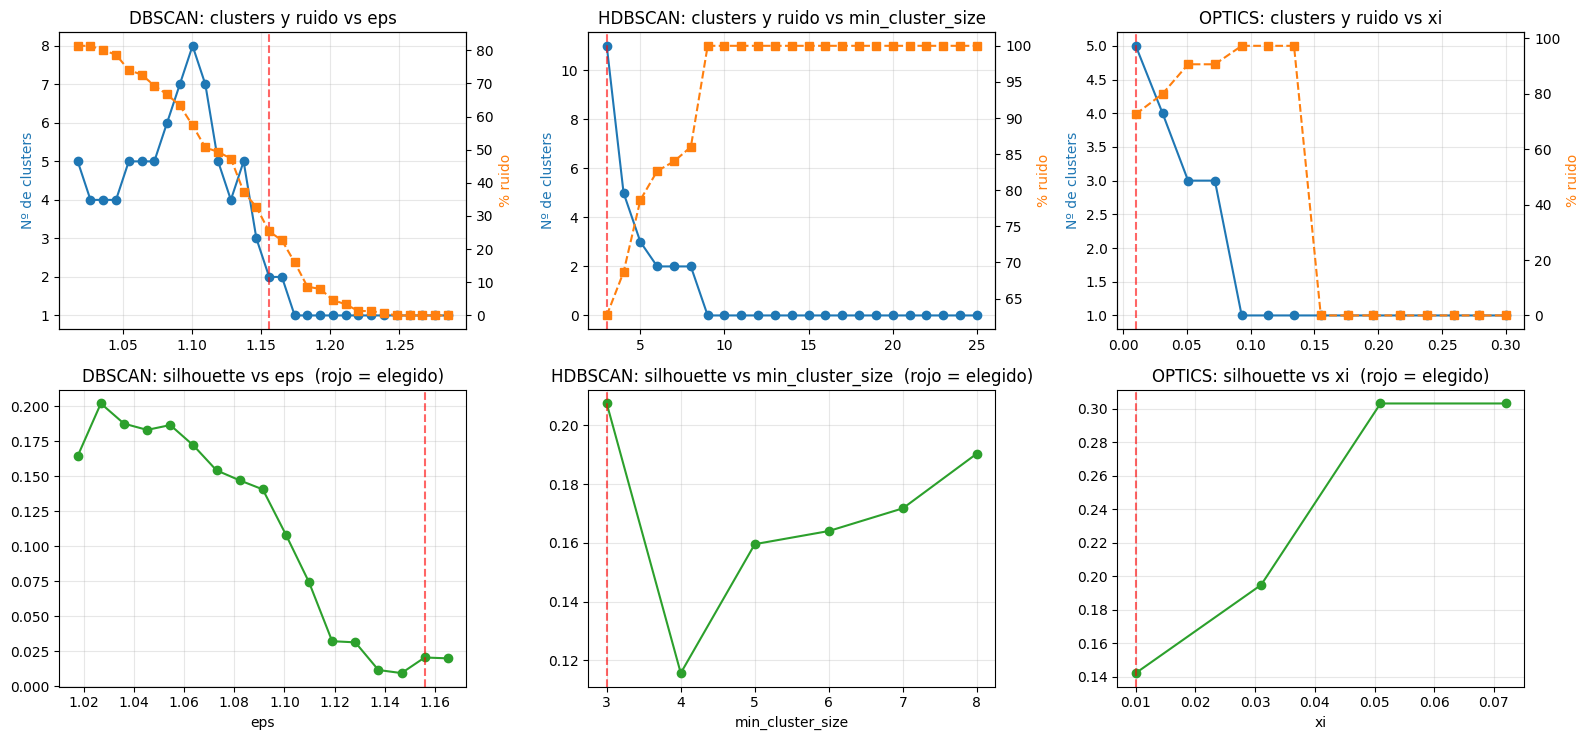

In [5]:
fig, axs = plt.subplots(2, 3, figsize=(16, 7.5))
for j, (alg, (d, par, elegido)) in enumerate(corridas[REPR]["sweeps"].items()):
    ax = axs[0, j]; ax.plot(d[par], d.n_clusters, "o-", color="tab:blue"); ax.set_ylabel("Nº de clusters", color="tab:blue")
    ax2 = ax.twinx(); ax2.plot(d[par], d.ruido * 100, "s--", color="tab:orange"); ax2.set_ylabel("% ruido", color="tab:orange")
    ax.axvline(elegido, color="red", ls="--", alpha=.6); ax.set_title(f"{alg}: clusters y ruido vs {par}"); ax.grid(alpha=.3)
    axs[1, j].plot(d[par], d.silhouette, "o-", color="tab:green"); axs[1, j].axvline(elegido, color="red", ls="--", alpha=.6)
    axs[1, j].set_title(f"{alg}: silhouette vs {par}  (rojo = elegido)"); axs[1, j].set_xlabel(par); axs[1, j].grid(alpha=.3)
plt.tight_layout(); guardar("N01_barrido_parametros.png"); plt.show()

## 5) Los 5 modelos sobre el mismo mapa de noticias (t-SNE)
Primer panel: **áreas reales**. Los otros cinco: lo que **descubrió cada algoritmo** sin ver las áreas (gris = ruido).

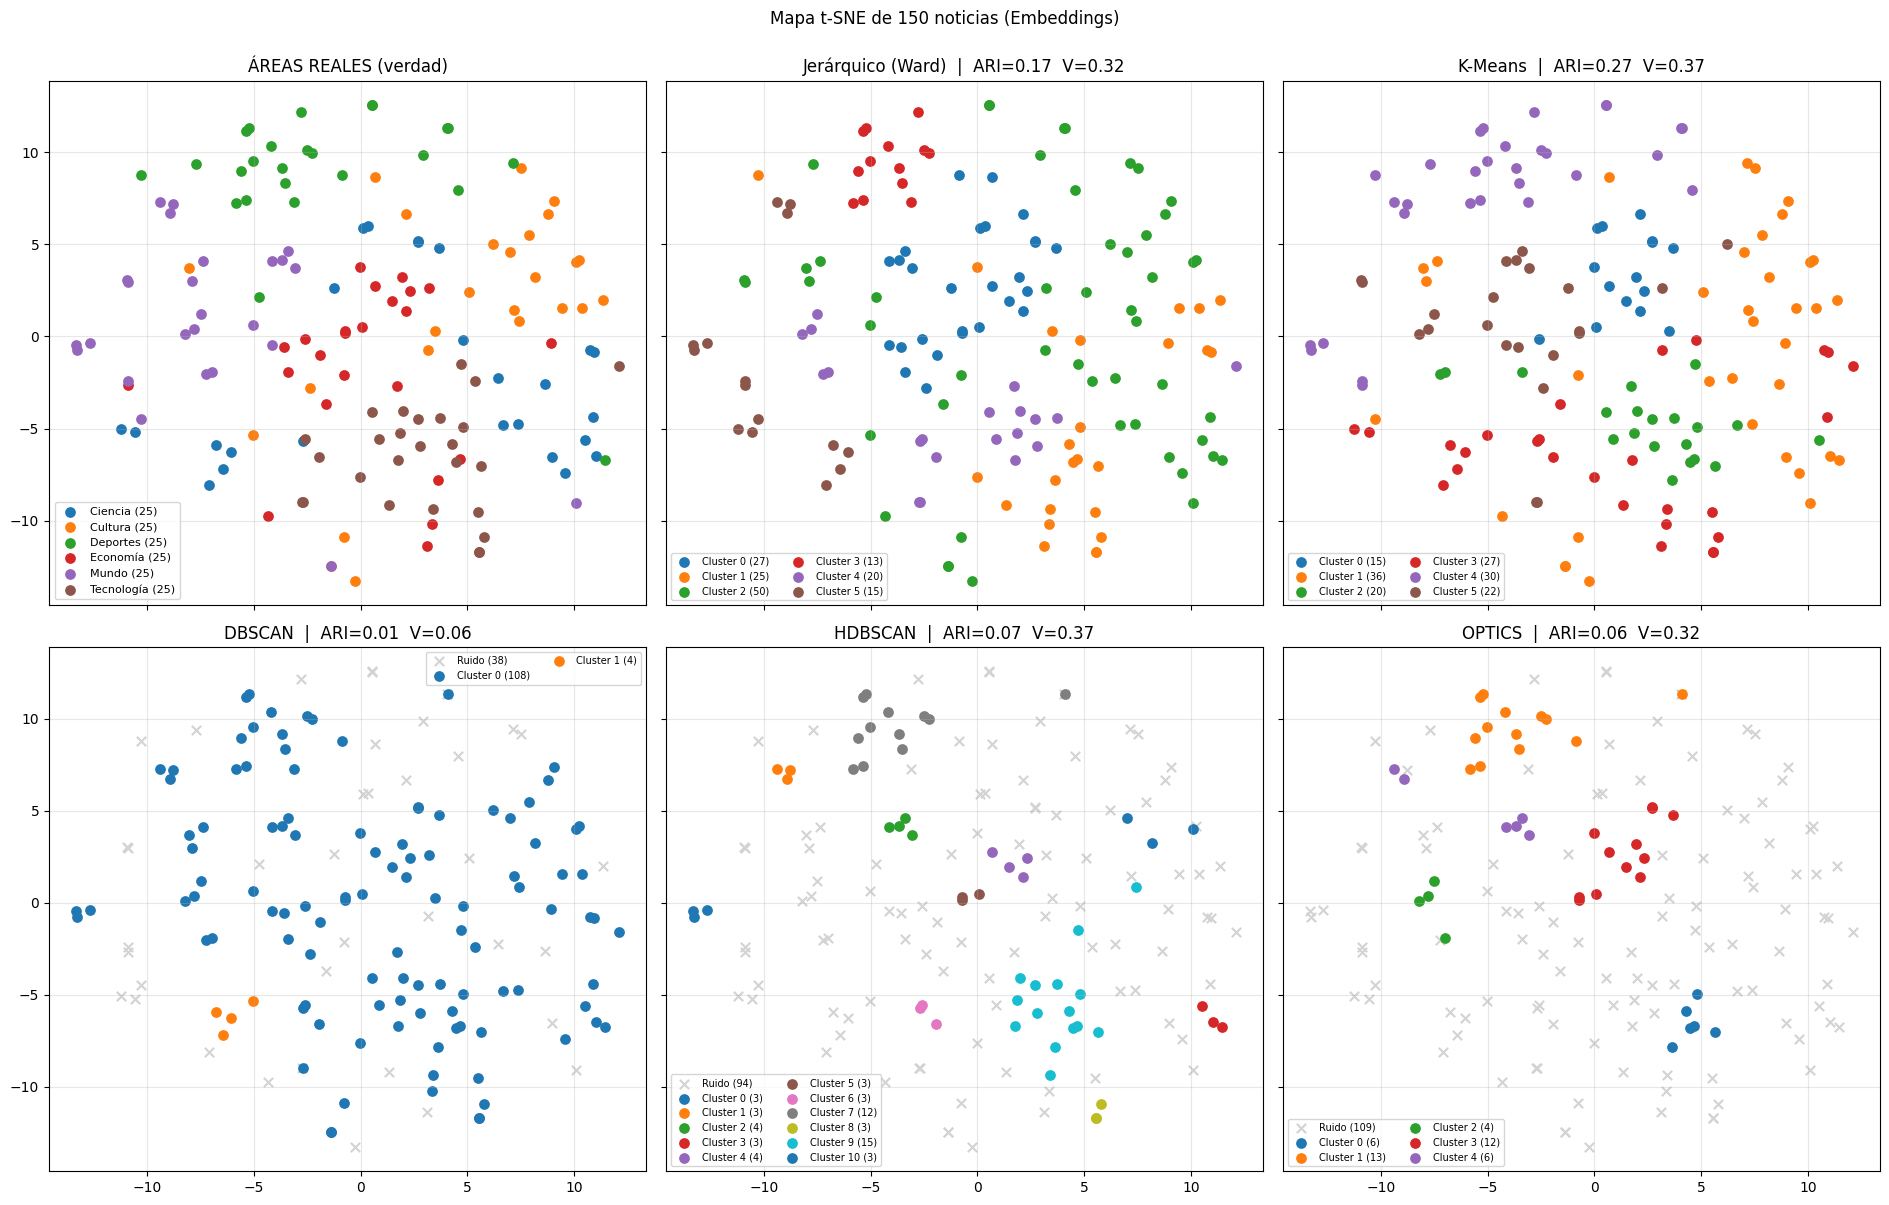

In [6]:
from sklearn.manifold import TSNE
perp = int(min(30, max(5, (n_docs - 1) // 3)))
XY = TSNE(n_components=2, perplexity=perp, metric="cosine", init="pca", random_state=SEMILLA).fit_transform(Xp)

fig, axs = plt.subplots(2, 3, figsize=(19, 12), sharex=True, sharey=True)
ax = axs[0, 0]
for a in areas:
    m = y_area == a; ax.scatter(XY[m, 0], XY[m, 1], s=45, color=COL_AREA[a], label=f"{a} ({m.sum()})")
ax.set_title("ÁREAS REALES (verdad)"); ax.legend(fontsize=8)
for ax, alg in zip(axs.flatten()[1:], ALGS):
    lab = labs_p[alg]
    for k in sorted(set(lab)):
        m = lab == k
        ax.scatter(XY[m, 0], XY[m, 1], s=45, color=color_cluster(k), marker="x" if k == -1 else "o", label=f"{nombre_cluster(k)} ({m.sum()})")
    ax.set_title(f"{alg}  |  ARI={tabla_p.loc[alg, 'ARI']:.2f}  V={tabla_p.loc[alg, 'V_measure']:.2f}"); ax.legend(fontsize=7, ncol=2)
for ax in axs.flatten(): ax.grid(alpha=.3)
plt.suptitle(f"Mapa t-SNE de {n_docs} noticias ({REPR})", y=1.0); plt.tight_layout(); guardar("N02_tsne_5_algoritmos.png"); plt.show()

## 6) ¿De qué área es cada cluster? (patrones temáticos)
Para cada algoritmo: matriz **cluster × área real** (porcentaje de cada cluster que pertenece a cada área) y tabla con el **área dominante, la pureza y las palabras que más caracterizan** al cluster (TF-IDF promedio del cluster menos el promedio global).
Así se ve qué "tema" encontró cada modelo, incluso cuando mezcla áreas (p. ej. *economía + tecnología*).

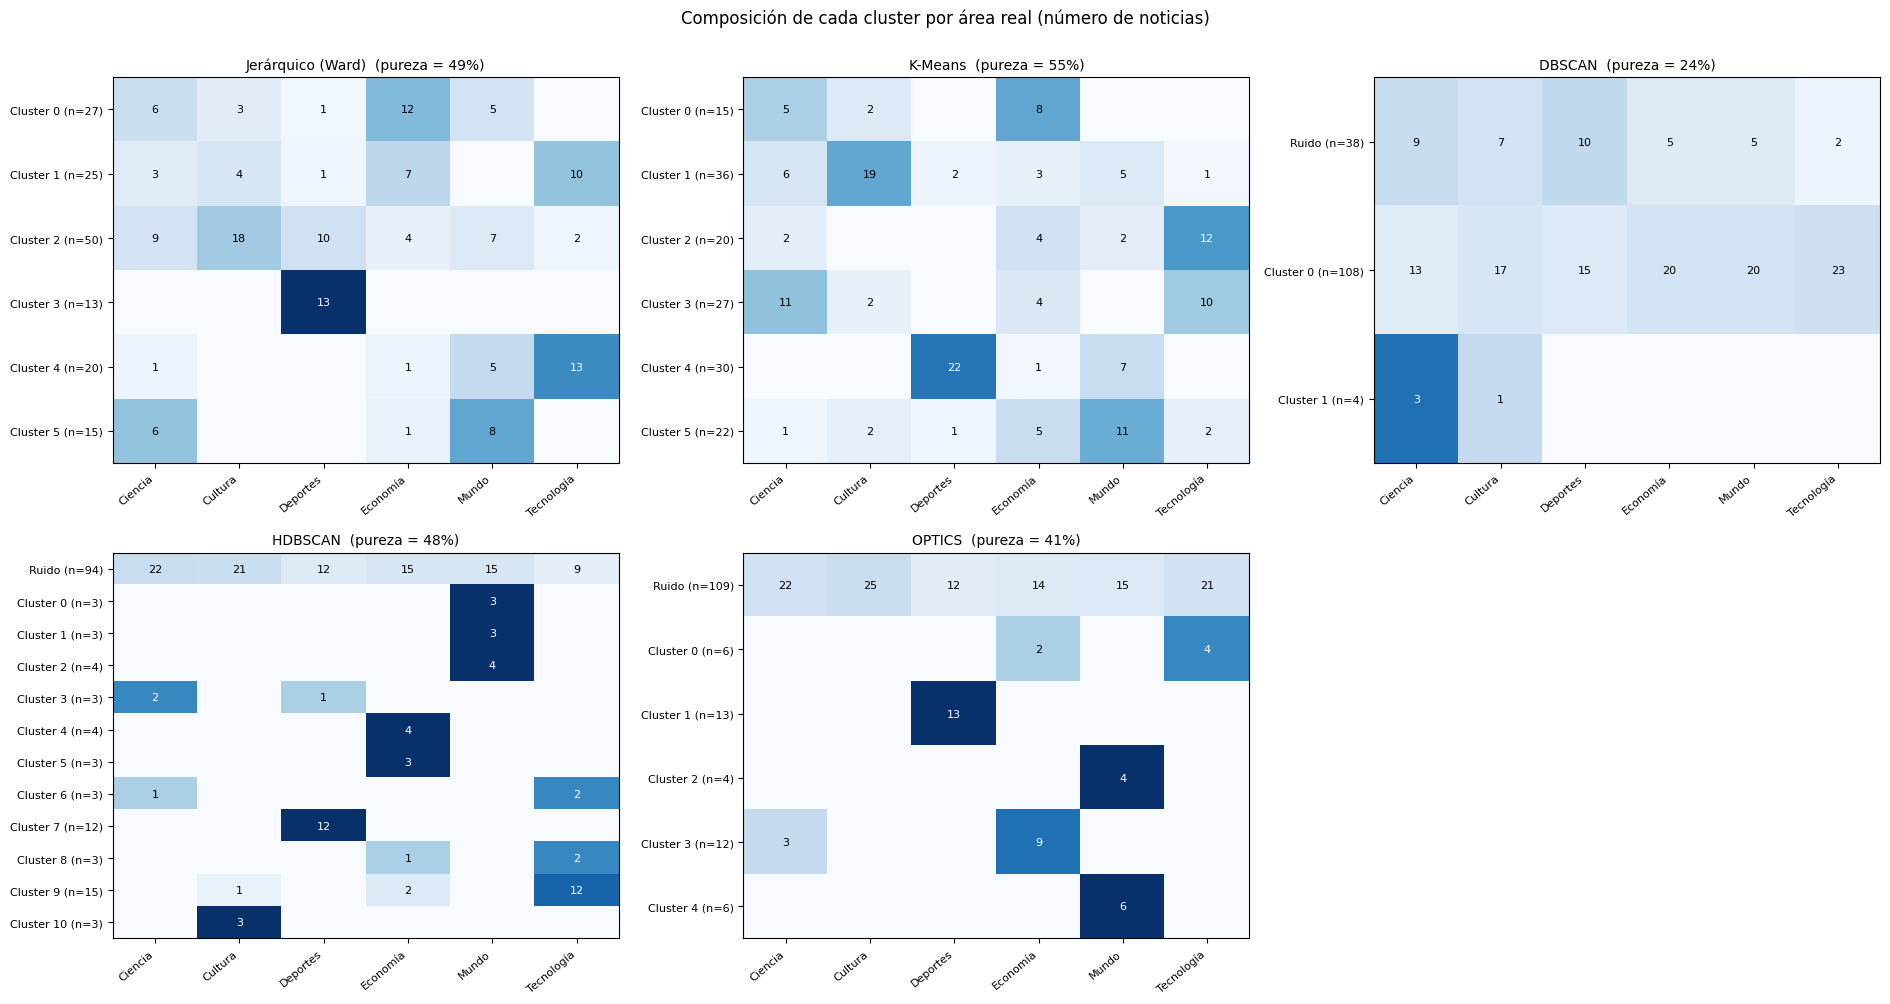

In [7]:
fig, axs = plt.subplots(2, 3, figsize=(19, 10))
for ax in axs.flatten(): ax.axis("off")
for ax, alg in zip(axs.flatten(), ALGS):
    ax.axis("on")
    tab = pd.crosstab(labs_p[alg], y_area).reindex(columns=areas, fill_value=0)
    pct = tab.div(tab.sum(axis=1), axis=0) * 100
    ax.imshow(pct.values, cmap="Blues", vmin=0, vmax=100, aspect="auto")
    ax.set_xticks(range(len(areas))); ax.set_xticklabels(areas, rotation=40, ha="right", fontsize=8)
    ax.set_yticks(range(len(tab))); ax.set_yticklabels([f"{nombre_cluster(k)} (n={tab.loc[k].sum()})" for k in tab.index], fontsize=8)
    for i in range(tab.shape[0]):
        for j in range(tab.shape[1]):
            if tab.values[i, j]: ax.text(j, i, tab.values[i, j], ha="center", va="center", fontsize=8,
                                          color="white" if pct.values[i, j] > 55 else "black")
    ax.set_title(f"{alg}  (pureza = {tabla_p.loc[alg, 'pureza']:.0%})", fontsize=10)
plt.suptitle("Composición de cada cluster por área real (número de noticias)", y=1.0); plt.tight_layout(); guardar("N03_cluster_vs_area.png"); plt.show()

In [8]:
def terminos_cluster(lab, k, n=8):
    m = lab == k
    d = np.asarray(X_tfidf[m].mean(axis=0)).ravel() - np.asarray(X_tfidf.mean(axis=0)).ravel()
    return ", ".join(vocab[np.argsort(d)[::-1][:n]])

def resumen_clusters(alg, lab):
    filas = []
    for k in sorted(set(lab), key=lambda x: (x == -1, x)):
        m = lab == k; vc = pd.Series(y_area[m]).value_counts()
        filas.append({"cluster": nombre_cluster(k), "n": int(m.sum()), "área dominante": vc.index[0],
                      "pureza": round(vc.iloc[0] / m.sum(), 2), "2.º área": vc.index[1] if len(vc) > 1 else "—",
                      "palabras características": terminos_cluster(lab, k) if k != -1 else "(noticias que no encajan en ningún grupo)"})
    return pd.DataFrame(filas)

pd.set_option("display.max_colwidth", 90)
for alg in ALGS:
    print(f"\n━━━ {alg}  ({corridas[REPR]['params'][alg]}) ━━━")
    display(resumen_clusters(alg, labs_p[alg]))


━━━ Jerárquico (Ward)  (k=6) ━━━


,cluster,n,área dominante,pureza,2.º área,palabras características
0,Cluster 0,27,Economía,0.44,Ciencia,"scotland, budget, energy, trump, fed, election, rate, elections"
1,Cluster 1,25,Tecnología,0.40,Economía,"company, anthropic, sold, listing, housing, stock, boom, auction"
2,Cluster 2,50,Cultura,0.36,Deportes,"life, film, music, game, experts, johnson, tv, series"
3,Cluster 3,13,Deportes,1.00,—,"chelsea, win, league, champions, champions league, penalty, arsenal, women champions"
4,Cluster 4,20,Tecnología,0.65,Mundo,"ai, use, uk, musk, apple, health, drones, drone"
5,Cluster 5,15,Mundo,0.53,Ciencia,"crash, passengers, train, brazil, spain, artemis, bolsonaro, cruise"



━━━ K-Means  (k=6) ━━━


,cluster,n,área dominante,pureza,2.º área,palabras características
0,Cluster 0,15,Economía,0.53,Ciencia,"scotland, budget, energy, prices, housing, year, scotland recycling, rate"
1,Cluster 1,36,Cultura,0.53,Ciencia,"music, life, film, died, court, new, johnson, tv"
2,Cluster 2,20,Tecnología,0.60,Economía,"ai, anthropic, uk, health, ways, africa, company, group"
3,Cluster 3,27,Ciencia,0.41,Tecnología,"musk, region, artemis, elon, elon musk, billion, years, profit"
4,Cluster 4,30,Deportes,0.73,Mundo,"chelsea, league, win, crash, passengers, finals, brazil, train"
5,Cluster 5,22,Mundo,0.50,Economía,"israel, canada, election, elections, apple, fed, attacker, cook"



━━━ DBSCAN  (eps=1.156 (mejor silhouette interno)) ━━━


,cluster,n,área dominante,pureza,2.º área,palabras características
0,Cluster 0,108,Tecnología,0.21,Mundo,"ai, israel, uk, budget, chelsea, election, film, league"
1,Cluster 1,4,Ciencia,0.75,Cultura,"artemis, 2028, nasa, moon, probably, 2026, planet, known"
2,Ruido,38,Deportes,0.26,Ciencia,(noticias que no encajan en ningún grupo)



━━━ HDBSCAN  (min_cluster_size=3 (menor ruido con >= 2 clusters (ningún valor cumplió los límites))) ━━━


,cluster,n,área dominante,pureza,2.º área,palabras características
0,Cluster 0,3,Mundo,1.00,—,"crash, train, spain, train crash, toledo, crash spain, high speed, 68"
1,Cluster 1,3,Mundo,1.00,—,"brazil, bolsonaro, miami, fleeing, flavio bolsonaro, flavio, fleeing brazil, landing"
2,Cluster 2,4,Mundo,1.00,—,"israel, netanyahu, election, 85, counted, outcome, bloc, israel election"
3,Cluster 3,3,Ciencia,0.67,Deportes,"brain, brain disease, disease, players, football, new study, study, researchers"
4,Cluster 4,4,Economía,1.00,—,"budget, chancellor, energy, bills, energy bills, economic, living, healey"
5,Cluster 5,3,Economía,1.00,—,"fed, rate, reserve, federal, federal reserve, rates, left, reserve left"
6,Cluster 6,3,Tecnología,0.67,Ciencia,"musk, elon musk, elon, satellite, genius, russian, putin, russian president"
7,Cluster 7,12,Deportes,1.00,—,"chelsea, league, champions, champions league, penalty, arsenal, win, women champions"
8,Cluster 8,3,Tecnología,0.67,Economía,"workers, microsoft, workers looks, profits soar, 000 workers, curb, days announcing, c..."
9,Cluster 9,15,Tecnología,0.80,Economía,"ai, anthropic, valley, silicon valley, silicon, uk, company, companies"



━━━ OPTICS  (xi=0.01 (menor ruido con >= 2 clusters (ningún valor cumplió los límites))) ━━━


,cluster,n,área dominante,pureza,2.º área,palabras características
0,Cluster 0,6,Tecnología,0.67,Economía,"anthropic, company, ai, stock, blockbuster share, share listing, share, public"
1,Cluster 1,13,Deportes,1.00,—,"chelsea, league, cup, champions, champions league, penalty, arsenal, win"
2,Cluster 2,4,Mundo,1.00,—,"forces, official, civilians, sudanese, mass, power, military, africa"
3,Cluster 3,12,Economía,0.75,Ciencia,"budget, rate, year, rates, fed, prices, kevin, scotland recycling"
4,Cluster 4,6,Mundo,1.00,—,"israel, election, netanyahu, brazil, counted, 85, outcome, bolsonaro"
5,Ruido,109,Cultura,0.23,Ciencia,(noticias que no encajan en ningún grupo)


## 7) Dendrograma, centroides y gráfica de alcanzabilidad (qué "aprende" cada modelo)
- **Jerárquico:** el dendrograma muestra qué áreas se parecen entre sí (se fusionan primero).
- **K-Means:** aprende **centroides**; cada centroide es una "noticia promedio" del grupo. Abajo se ve qué palabras pesan más en cada centroide.
- **OPTICS:** la gráfica de alcanzabilidad muestra valles (grupos densos) y picos (fronteras).
- **HDBSCAN:** entrega una **probabilidad de pertenencia** por noticia; las de baja probabilidad son noticias "de frontera".

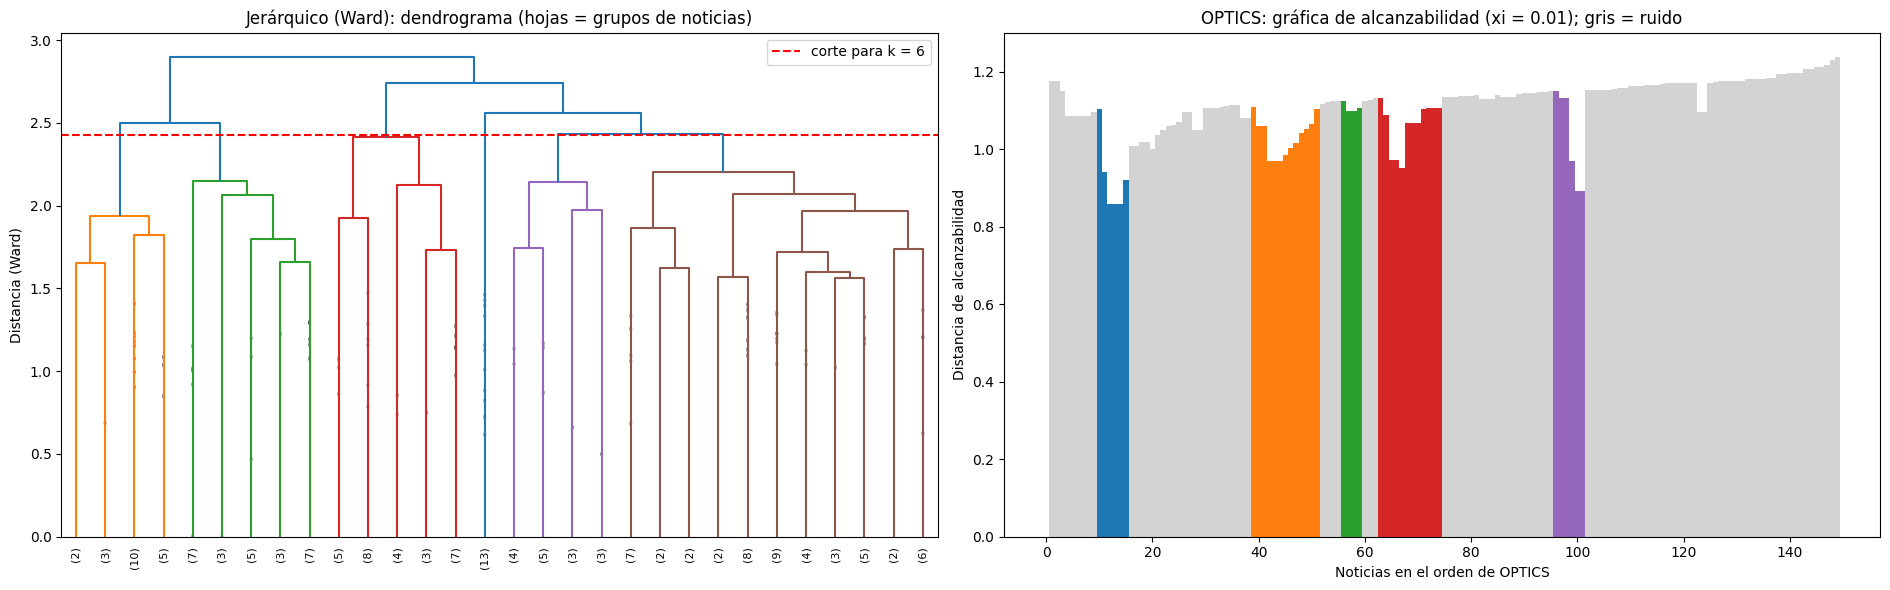

K-Means — palabras que más pesan en cada centroide:
  Centroide 0 (n=15, área dominante: Economía): scotland, budget, energy, prices, housing, year, scotland recycling, rate, ireland, northern ireland
  Centroide 1 (n=36, área dominante: Cultura): music, life, film, died, court, new, johnson, tv, study, like
  Centroide 2 (n=20, área dominante: Tecnología): ai, anthropic, uk, health, ways, africa, company, group, ebola, near
  Centroide 3 (n=27, área dominante: Ciencia): musk, region, artemis, elon, elon musk, billion, years, profit, build, factory
  Centroide 4 (n=30, área dominante: Deportes): chelsea, league, win, crash, passengers, finals, brazil, train, spain, extension
  Centroide 5 (n=22, área dominante: Mundo): israel, canada, election, elections, apple, fed, attacker, cook, trump, midterms


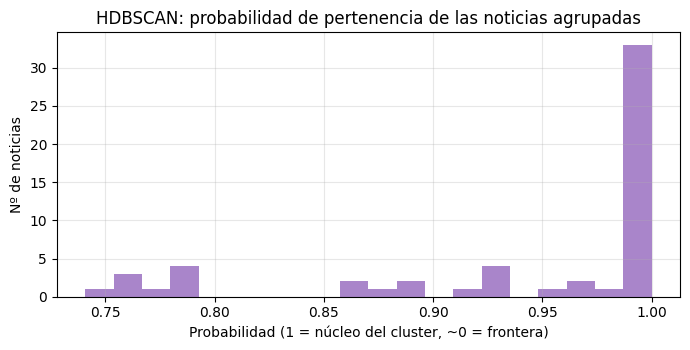

In [9]:
from scipy.cluster.hierarchy import dendrogram, linkage

fig, axs = plt.subplots(1, 2, figsize=(19, 6))
# (a) Dendrograma
Z = linkage(Xp, method="ward")
corte = (Z[-K_TXT, 2] + Z[-(K_TXT - 1), 2]) / 2 if K_TXT > 1 else None
dendrogram(Z, truncate_mode="lastp", p=min(30, n_docs), leaf_rotation=90, leaf_font_size=8, show_contracted=True,
           color_threshold=corte, ax=axs[0])
axs[0].axhline(corte, color="red", ls="--", label=f"corte para k = {K_TXT}"); axs[0].legend()
axs[0].set_title("Jerárquico (Ward): dendrograma (hojas = grupos de noticias)"); axs[0].set_ylabel("Distancia (Ward)")
# (b) Alcanzabilidad de OPTICS
xi_opt = corridas[REPR]["sweeps"]["OPTICS"][2]
opt = OPTICS(min_samples=MIN_SAMPLES, xi=float(xi_opt)).fit(Xp)
orden = opt.ordering_; reach = opt.reachability_[orden].copy(); reach[~np.isfinite(reach)] = np.nan
axs[1].bar(range(len(reach)), np.nan_to_num(reach), width=1.0, color=[color_cluster(k) for k in opt.labels_[orden]])
axs[1].set_title(f"OPTICS: gráfica de alcanzabilidad (xi = {xi_opt}); gris = ruido")
axs[1].set_xlabel("Noticias en el orden de OPTICS"); axs[1].set_ylabel("Distancia de alcanzabilidad")
plt.tight_layout(); guardar("N04_dendrograma_alcanzabilidad.png"); plt.show()

# (c) Centroides de K-Means (en el espacio TF-IDF) y probabilidades de HDBSCAN
lab_km = labs_p["K-Means"]
print("K-Means — palabras que más pesan en cada centroide:")
for k in range(K_TXT):
    vc = pd.Series(y_area[lab_km == k]).value_counts()
    print(f"  Centroide {k} (n={(lab_km == k).sum()}, área dominante: {vc.index[0]}): {terminos_cluster(lab_km, k, 10)}")

hdb = HDBSCAN(min_cluster_size=int(corridas[REPR]["sweeps"]["HDBSCAN"][2])).fit(Xp)
if hasattr(hdb, "probabilities_"):
    pr = hdb.probabilities_; lab_h = hdb.labels_
    plt.figure(figsize=(7, 3.6)); plt.hist(pr[lab_h != -1], bins=20, color="tab:purple", alpha=.8)
    plt.title("HDBSCAN: probabilidad de pertenencia de las noticias agrupadas")
    plt.xlabel("Probabilidad (1 = núcleo del cluster, ~0 = frontera)"); plt.ylabel("Nº de noticias"); plt.grid(alpha=.3)
    plt.tight_layout(); guardar("N05_hdbscan_probabilidades.png"); plt.show()

## 8) Comparación final: ¿en qué se diferencian los modelos?

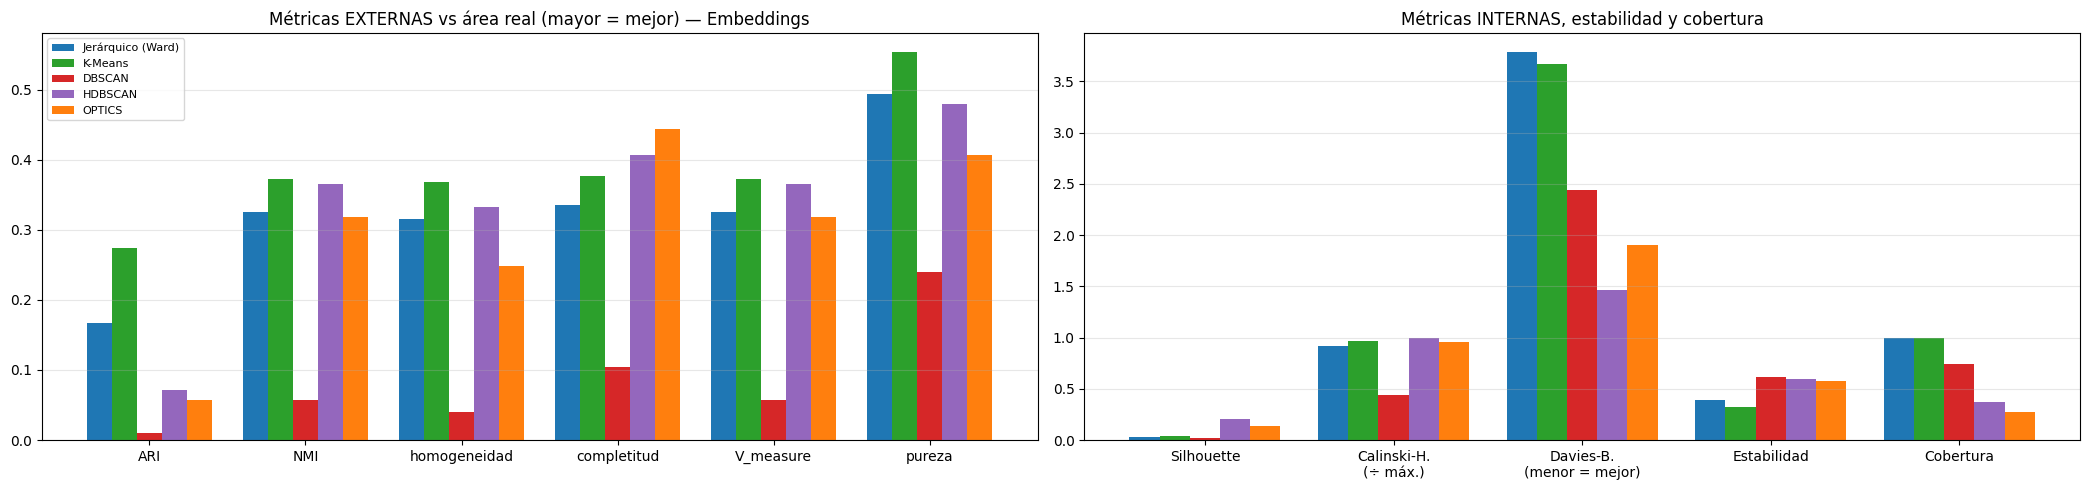

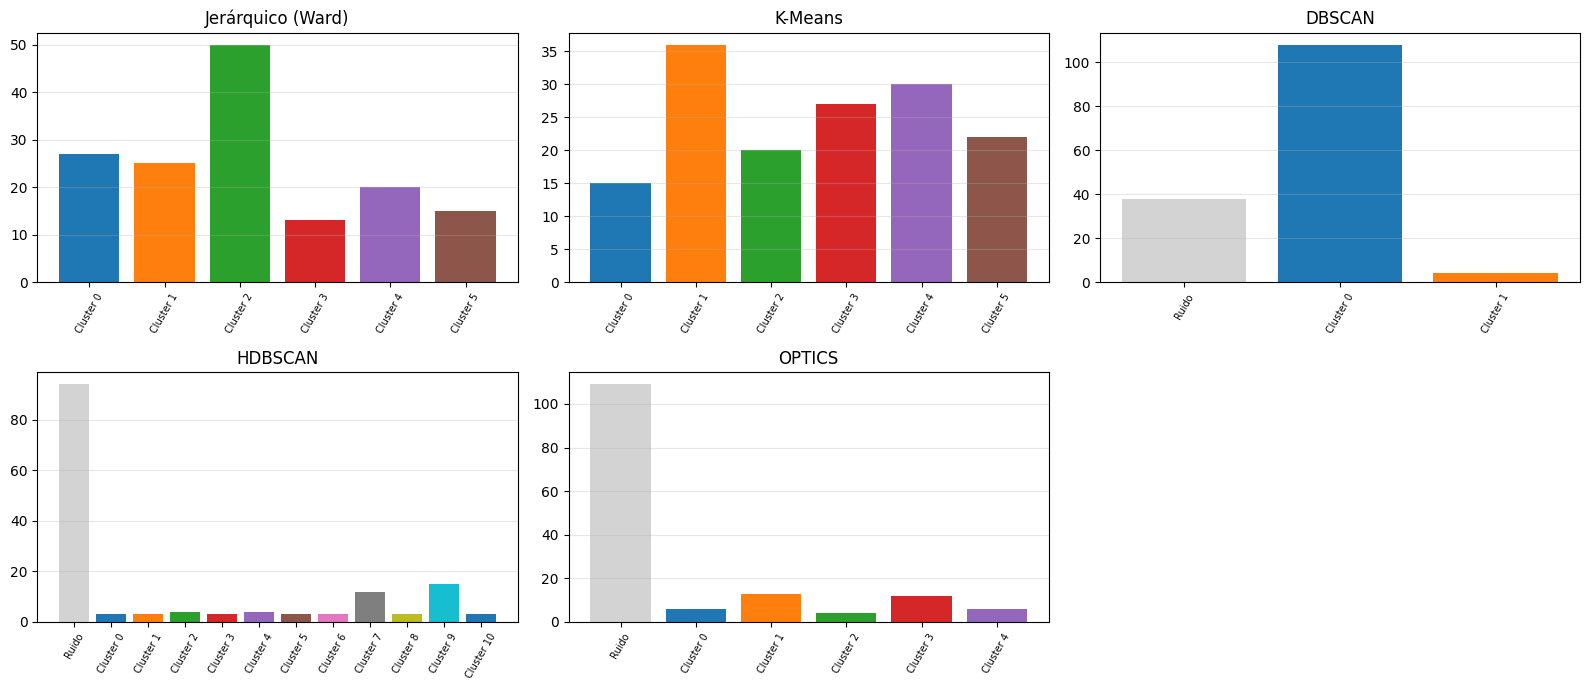

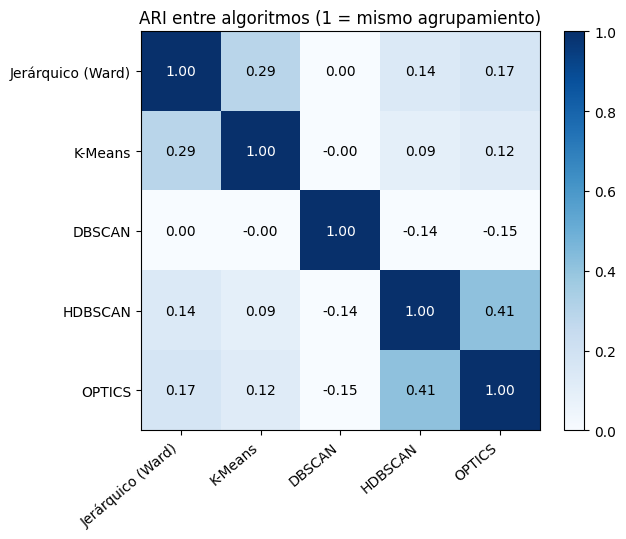

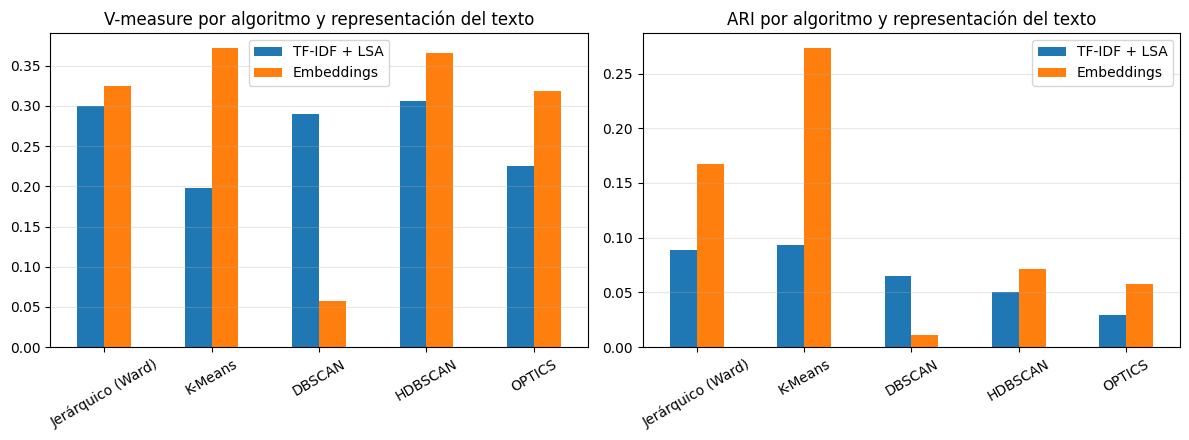

In [10]:
# ---- (a) Métricas externas: ¿reproducen las áreas reales? ----
ext = ["ARI", "NMI", "homogeneidad", "completitud", "V_measure", "pureza"]
fig, axs = plt.subplots(1, 2, figsize=(21, 5))
w = 0.8 / len(ALGS)
for i, a in enumerate(ALGS):
    axs[0].bar(np.arange(len(ext)) + i * w, tabla_p.loc[a, ext].astype(float).values, w, color=COL_ALG[a], label=a)
axs[0].set_xticks(np.arange(len(ext)) + 0.4 - w / 2); axs[0].set_xticklabels(ext)
axs[0].set_title(f"Métricas EXTERNAS vs área real (mayor = mejor) — {REPR}"); axs[0].legend(fontsize=8); axs[0].grid(alpha=.3, axis="y")

# ---- (b) Métricas internas, estabilidad y cobertura ----
internas = [("silhouette", "Silhouette"), ("calinski", "Calinski-H.\n(÷ máx.)"), ("davies_bouldin", "Davies-B.\n(menor = mejor)"),
            ("estabilidad_ARI", "Estabilidad"), ("cobertura", "Cobertura")]
tp = tabla_p.copy(); tp["calinski"] = tp["calinski"].astype(float) / (tp["calinski"].astype(float).max() or 1)
for i, a in enumerate(ALGS):
    axs[1].bar(np.arange(len(internas)) + i * w, np.nan_to_num(tp.loc[a, [c for c, _ in internas]].astype(float).values), w, color=COL_ALG[a], label=a)
axs[1].set_xticks(np.arange(len(internas)) + 0.4 - w / 2); axs[1].set_xticklabels([t for _, t in internas])
axs[1].set_title("Métricas INTERNAS, estabilidad y cobertura"); axs[1].grid(alpha=.3, axis="y")
plt.tight_layout(); guardar("N06_metricas_5_algoritmos.png"); plt.show()

# ---- (c) Tamaños de cluster ----
fig, axs = plt.subplots(2, 3, figsize=(16, 7))
for ax in axs.flatten(): ax.axis("off")
for ax, a in zip(axs.flatten(), ALGS):
    ax.axis("on"); vc = pd.Series(labs_p[a]).value_counts().sort_index()
    ax.bar([nombre_cluster(k) for k in vc.index], vc.values, color=[color_cluster(k) for k in vc.index])
    ax.set_title(a); ax.tick_params(axis="x", rotation=60, labelsize=7); ax.grid(alpha=.3, axis="y")
plt.tight_layout(); guardar("N07_tamanos_clusters.png"); plt.show()

# ---- (d) Acuerdo entre algoritmos ----
ari_m = pd.DataFrame([[adjusted_rand_score(labs_p[a], labs_p[b]) for b in ALGS] for a in ALGS], index=ALGS, columns=ALGS)
plt.figure(figsize=(6.5, 5.5)); plt.imshow(ari_m.values, cmap="Blues", vmin=0, vmax=1)
plt.xticks(range(5), ALGS, rotation=40, ha="right"); plt.yticks(range(5), ALGS)
for i in range(5):
    for j in range(5): plt.text(j, i, f"{ari_m.values[i, j]:.2f}", ha="center", va="center", color="white" if ari_m.values[i, j] > .6 else "black")
plt.title("ARI entre algoritmos (1 = mismo agrupamiento)"); plt.colorbar(fraction=.046); plt.tight_layout(); guardar("N08_acuerdo.png"); plt.show()

# ---- (e) TF-IDF/LSA vs Embeddings: ¿importa cómo se representa el texto? ----
if len(corridas) > 1:
    comp = pd.DataFrame({r: corridas[r]["tabla"]["V_measure"].astype(float) for r in corridas})
    comp_ari = pd.DataFrame({r: corridas[r]["tabla"]["ARI"].astype(float) for r in corridas})
    fig, axs = plt.subplots(1, 2, figsize=(12, 4.5))
    for ax, d, t in zip(axs, (comp, comp_ari), ("V-measure", "ARI")):
        d.plot(kind="bar", ax=ax, rot=30); ax.set_title(f"{t} por algoritmo y representación del texto"); ax.grid(alpha=.3, axis="y")
    plt.tight_layout(); guardar("N09_representaciones.png"); plt.show()
else:
    print("Solo hay una representación (activa USAR_EMBEDDINGS = True para comparar TF-IDF vs embeddings).")

Ranking (1 = mejor) con la representación 'Embeddings':


,"puesto_externo (ARI, NMI, V)","puesto_interno (Sil, CH, DB)",puesto_estab+cobertura,puesto_global
HDBSCAN,2.33,1.00,3.0,2.11
K-Means,1.00,3.00,3.0,2.33
Jerárquico (Ward),2.67,4.33,2.5,3.17
OPTICS,4.00,2.33,4.0,3.44
DBSCAN,5.00,4.33,2.0,3.78


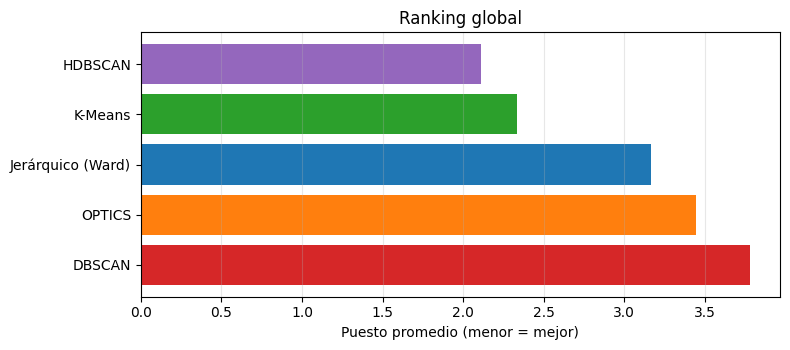


>>> Mejor global: HDBSCAN
>>> Mejor reproduciendo las áreas reales (V-measure): K-Means
>>> Mejor estabilidad: DBSCAN
⚠ HDBSCAN dejó 63 % de las noticias como ruido: sus métricas internas son poco comparables.
⚠ OPTICS dejó 73 % de las noticias como ruido: sus métricas internas son poco comparables.


In [11]:
# ---------------- Ranking ----------------
def rank(col, mayor): return tabla_p[col].astype(float).rank(ascending=not mayor, method="min", na_option="bottom")
rk = pd.DataFrame({
    "puesto_externo (ARI, NMI, V)": pd.concat([rank("ARI", True), rank("NMI", True), rank("V_measure", True)], axis=1).mean(axis=1),
    "puesto_interno (Sil, CH, DB)": pd.concat([rank("silhouette", True), rank("calinski", True), rank("davies_bouldin", False)], axis=1).mean(axis=1),
    "puesto_estab+cobertura":       pd.concat([rank("estabilidad_ARI", True), rank("cobertura", True)], axis=1).mean(axis=1),
})
rk["puesto_global"] = rk.mean(axis=1)
rk = rk.sort_values("puesto_global")
print(f"Ranking (1 = mejor) con la representación '{REPR}':")
display(rk.round(2))
plt.figure(figsize=(8, 3.6)); plt.barh(rk.index[::-1], rk["puesto_global"][::-1], color=[COL_ALG[a] for a in rk.index[::-1]])
plt.xlabel("Puesto promedio (menor = mejor)"); plt.title("Ranking global"); plt.grid(alpha=.3, axis="x")
plt.tight_layout(); guardar("N10_ranking.png"); plt.show()

print(f"\n>>> Mejor global: {rk.index[0]}")
print(f">>> Mejor reproduciendo las áreas reales (V-measure): {tabla_p['V_measure'].astype(float).idxmax()}")
print(f">>> Mejor estabilidad: {tabla_p['estabilidad_ARI'].astype(float).idxmax()}")
for a in ("DBSCAN", "HDBSCAN", "OPTICS"):
    if tabla_p.loc[a, "ruido_pct"] > 100 * MAX_RUIDO:
        print(f"⚠ {a} dejó {tabla_p.loc[a, 'ruido_pct']:.0f} % de las noticias como ruido: sus métricas internas son poco comparables.")
    if tabla_p.loc[a, "cluster_mayor_pct"] > 80:
        print(f"⚠ {a} metió >80 % de las noticias en un solo cluster: casi no está separando.")

## 9) Noticias "difíciles": mal agrupadas y ruido
Son las que más enseñan: suelen ser noticias **entre dos áreas** (p. ej. una empresa tecnológica en bolsa = Economía + Tecnología; el deporte como negocio = Deportes + Economía).

In [12]:
def noticias_dificiles(alg, max_filas=8):
    lab = labs_p[alg]
    dom = {k: pd.Series(y_area[lab == k]).value_counts().index[0] for k in set(lab) if k != -1}
    filas = []
    for i, (k, a) in enumerate(zip(lab, y_area)):
        if k == -1:
            filas.append((noticias.titulo.iloc[i], a, "Ruido", "—"))
        elif dom[k] != a:
            filas.append((noticias.titulo.iloc[i], a, nombre_cluster(k), dom[k]))
    return pd.DataFrame(filas, columns=["noticia", "área real", "dónde cayó", "área dominante de ese cluster"]), len(filas)

for alg in ALGS:
    d, n = noticias_dificiles(alg)
    print(f"\n━━━ {alg}: {n} de {n_docs} noticias ({n / n_docs:.0%}) no encajan con el área dominante de su cluster ━━━")
    if n: display(d.head(8))


━━━ Jerárquico (Ward): 76 de 150 noticias (51%) no encajan con el área dominante de su cluster ━━━


,noticia,área real,dónde cayó,área dominante de ese cluster
0,Egypt fines prominent editor Lina Attalah and shuts independent news outlet Mada Masr,Mundo,Cluster 2,Cultura
1,"Africa’s ‘unprecedented’ Ebola outbreak could reach UK, says top health official",Mundo,Cluster 4,Tecnología
2,"Rivals in Israel Election Strike Tone of Triumph, but Outcome Is Far From Clear",Mundo,Cluster 0,Economía
3,UK sanctions Sudanese military leaders implicated in El Fasher ‘campaign of rape’,Mundo,Cluster 4,Tecnología
4,Nigeria’s Ebola Patient Evacuated as Investigators Press for Answers,Mundo,Cluster 4,Tecnología
5,"Netanyahu's bloc leading Israel election but short of majority, partial results show",Mundo,Cluster 0,Economía
6,US forces accused of ‘weaponising’ Somalia’s floods by trapping women and children in ...,Mundo,Cluster 4,Tecnología
7,Tommy Robinson Found Guilty of Harassing 2 UK Journalists,Mundo,Cluster 2,Cultura



━━━ K-Means: 67 de 150 noticias (45%) no encajan con el área dominante de su cluster ━━━


,noticia,área real,dónde cayó,área dominante de ese cluster
0,High-speed train crash kills at least 68 people in Spain,Mundo,Cluster 4,Deportes
1,Egypt fines prominent editor Lina Attalah and shuts independent news outlet Mada Masr,Mundo,Cluster 1,Cultura
2,"At Least 68 Killed in Train Crash in Spain, Officials Say",Mundo,Cluster 4,Deportes
3,"Bloodied, dazed and angry - how passengers' rail journey turned to disaster in Spain",Mundo,Cluster 4,Deportes
4,"Africa’s ‘unprecedented’ Ebola outbreak could reach UK, says top health official",Mundo,Cluster 2,Tecnología
5,Flávio Bolsonaro denies fleeing Brazil after landing in Miami,Mundo,Cluster 4,Deportes
6,Nigeria’s Ebola Patient Evacuated as Investigators Press for Answers,Mundo,Cluster 2,Tecnología
7,Tommy Robinson Found Guilty of Harassing 2 UK Journalists,Mundo,Cluster 1,Cultura



━━━ DBSCAN: 124 de 150 noticias (83%) no encajan con el área dominante de su cluster ━━━


,noticia,área real,dónde cayó,área dominante de ese cluster
0,High-speed train crash kills at least 68 people in Spain,Mundo,Cluster 0,Tecnología
1,Egypt fines prominent editor Lina Attalah and shuts independent news outlet Mada Masr,Mundo,Cluster 0,Tecnología
2,"At Least 68 Killed in Train Crash in Spain, Officials Say",Mundo,Cluster 0,Tecnología
3,"Bloodied, dazed and angry - how passengers' rail journey turned to disaster in Spain",Mundo,Cluster 0,Tecnología
4,"Africa’s ‘unprecedented’ Ebola outbreak could reach UK, says top health official",Mundo,Cluster 0,Tecnología
5,"Rivals in Israel Election Strike Tone of Triumph, but Outcome Is Far From Clear",Mundo,Cluster 0,Tecnología
6,Flávio Bolsonaro denies fleeing Brazil after landing in Miami,Mundo,Cluster 0,Tecnología
7,UK sanctions Sudanese military leaders implicated in El Fasher ‘campaign of rape’,Mundo,Cluster 0,Tecnología



━━━ HDBSCAN: 100 de 150 noticias (67%) no encajan con el área dominante de su cluster ━━━


,noticia,área real,dónde cayó,área dominante de ese cluster
0,Egypt fines prominent editor Lina Attalah and shuts independent news outlet Mada Masr,Mundo,Ruido,—
1,"Africa’s ‘unprecedented’ Ebola outbreak could reach UK, says top health official",Mundo,Ruido,—
2,UK sanctions Sudanese military leaders implicated in El Fasher ‘campaign of rape’,Mundo,Ruido,—
3,Nigeria’s Ebola Patient Evacuated as Investigators Press for Answers,Mundo,Ruido,—
4,US forces accused of ‘weaponising’ Somalia’s floods by trapping women and children in ...,Mundo,Ruido,—
5,Tommy Robinson Found Guilty of Harassing 2 UK Journalists,Mundo,Ruido,—
6,Sudan paramilitary drone strikes cause mass power cuts in eastern states,Mundo,Ruido,—
7,The Ocean ‘Was the Color of Chocolate.’ Mexico Declares War on Seaweed.,Mundo,Ruido,—



━━━ OPTICS: 114 de 150 noticias (76%) no encajan con el área dominante de su cluster ━━━


,noticia,área real,dónde cayó,área dominante de ese cluster
0,High-speed train crash kills at least 68 people in Spain,Mundo,Ruido,—
1,Egypt fines prominent editor Lina Attalah and shuts independent news outlet Mada Masr,Mundo,Ruido,—
2,"At Least 68 Killed in Train Crash in Spain, Officials Say",Mundo,Ruido,—
3,"Bloodied, dazed and angry - how passengers' rail journey turned to disaster in Spain",Mundo,Ruido,—
4,Flávio Bolsonaro denies fleeing Brazil after landing in Miami,Mundo,Ruido,—
5,Nigeria’s Ebola Patient Evacuated as Investigators Press for Answers,Mundo,Ruido,—
6,Tommy Robinson Found Guilty of Harassing 2 UK Journalists,Mundo,Ruido,—
7,The Ocean ‘Was the Color of Chocolate.’ Mexico Declares War on Seaweed.,Mundo,Ruido,—


## 10) Usar el modelo entrenado con una noticia nueva
K-Means (y el pipeline TF-IDF → LSA) **sí se puede reutilizar**: aprendió centroides, así que una noticia nueva se asigna al centroide más cercano.
(Jerárquico, DBSCAN, HDBSCAN y OPTICS no tienen un `predict` directo: habría que reajustarlos con la noticia incluida.)

In [13]:
km_texto = KMeans(n_clusters=K_TXT, n_init=10, random_state=SEMILLA).fit(X_lsa)
area_de_cluster = {k: pd.Series(y_area[km_texto.labels_ == k]).value_counts().index[0] for k in range(K_TXT)}

def asignar_noticia(texto):
    v = Normalizer().fit_transform(svd.transform(tfidf.transform([texto])))
    k = int(km_texto.predict(v)[0])
    return k, area_de_cluster[k], terminos_cluster(km_texto.labels_, k, 6)

ejemplos = ["The central bank raised interest rates again as inflation stayed high and markets fell",
            "The striker scored twice in the final to win the championship for his club",
            "Researchers discovered a new exoplanet using the space telescope",
            "The tech company unveiled a new artificial intelligence chip for data centres",
            "El presidente anunció nuevas sanciones tras la cumbre internacional"]
for t in ejemplos:
    k, a, termi = asignar_noticia(t)
    print(f"• {t[:80]}…\n   → cluster {k} | área probable: {a} | términos del cluster: {termi}")

• The central bank raised interest rates again as inflation stayed high and market…
   → cluster 2 | área probable: Economía | términos del cluster: budget, fed, fuel, living, december, uk
• The striker scored twice in the final to win the championship for his club…
   → cluster 1 | área probable: Deportes | términos del cluster: years, new, chelsea, game, players, just
• Researchers discovered a new exoplanet using the space telescope…
   → cluster 1 | área probable: Deportes | términos del cluster: years, new, chelsea, game, players, just
• The tech company unveiled a new artificial intelligence chip for data centres…
   → cluster 5 | área probable: Tecnología | términos del cluster: ai, musk, train, companies, crash, listing
• El presidente anunció nuevas sanciones tras la cumbre internacional…
   → cluster 0 | área probable: Cultura | términos del cluster: tv, wanted, backlash, singer, russell, died


## 11) Exportar resultados

In [14]:
res = noticias[["area", "fuente", "titulo", "resumen"]].copy()
for a in ALGS: res[f"cluster_{a}"] = labs_p[a]
res.insert(0, "id", res.index)
res.to_csv(os.path.join(RESULTADOS, "noticias_clusters_5_algoritmos.csv"), index=False)
for r in corridas: corridas[r]["tabla"].to_csv(os.path.join(RESULTADOS, f"comparacion_{r.replace(' ', '_').replace('+', '')}.csv"))
rk.to_csv(os.path.join(RESULTADOS, "ranking_algoritmos.csv"))
print("Archivos guardados en:", RESULTADOS)
res.head(10)

Archivos guardados en: ./ANALISIS_NOTICIAS/resultados


,id,area,fuente,titulo,resumen,cluster_Jerárquico (Ward),cluster_K-Means,cluster_DBSCAN,cluster_HDBSCAN,cluster_OPTICS
n000,n000,Mundo,BBC,High-speed train crash kills at least 68 people in Spain,"The crash, between a moving train and another that was stopped further up the track, w...",5,4,0,0,-1
n001,n001,Mundo,Guardian,Egypt fines prominent editor Lina Attalah and shuts independent news outlet Mada Masr,Warnings of escalating clampdown on press freedom come after Cairo court convicts Atta...,2,1,0,-1,-1
n002,n002,Mundo,NYT,"At Least 68 Killed in Train Crash in Spain, Officials Say","A high-speed passenger train rear-ended another near Toledo, months after a crash invo...",5,4,0,0,-1
n003,n003,Mundo,BBC,"Bloodied, dazed and angry - how passengers' rail journey turned to disaster in Spain","Survivors of the train crash in Spain have spoken of their shock, panic and anger at t...",5,4,0,0,-1
n004,n004,Mundo,Guardian,"Africa’s ‘unprecedented’ Ebola outbreak could reach UK, says top health official","Jean Kaseya, of the Africa CDC, warns of the illness spreading like Covid unless more ...",4,2,0,-1,2
n005,n005,Mundo,NYT,"Rivals in Israel Election Strike Tone of Triumph, but Outcome Is Far From Clear","Addressing supporters after midnight, Prime Minister Benjamin Netanyahu and Gadi Eisen...",0,5,0,2,4
n006,n006,Mundo,BBC,Flávio Bolsonaro denies fleeing Brazil after landing in Miami,The defeated Brazilian candidate claims to be the victim of a coup d’état and politica...,5,4,0,1,-1
n007,n007,Mundo,Guardian,UK sanctions Sudanese military leaders implicated in El Fasher ‘campaign of rape’,Commanders suspected of sexual violence during the largest and fastest slaughter of ci...,4,5,0,-1,2
n008,n008,Mundo,NYT,Nigeria’s Ebola Patient Evacuated as Investigators Press for Answers,"More than a week after the first case was reported in Africa’s most populous nation, p...",4,2,0,-1,-1
n009,n009,Mundo,BBC,"Netanyahu's bloc leading Israel election but short of majority, partial results show","With 85% of ballots counted, Netanyahu's Likud party and its allies are set to win 53 ...",0,5,0,2,4


## Cómo diferenciar los modelos (guía de lectura)

| | Jerárquico (Ward) | K-Means | DBSCAN | HDBSCAN | OPTICS |
|---|---|---|---|---|---|
| **¿Qué "aprende" del texto?** | Un árbol: qué noticias/áreas se fusionan primero | Centroides = "noticia promedio" de cada tema | Zonas densas de noticias parecidas | Zonas densas **de distinta densidad**, solo las más estables | Orden de alcanzabilidad: valles = temas |
| **Necesita k** | Sí | Sí | No | No | No |
| **Parámetros** | `k` | `k` | `eps`, `min_samples` | `min_cluster_size` | `min_samples`, `xi` |
| **Noticias sin tema claro** | Las obliga a un grupo | Las obliga a un grupo | Ruido (-1) | Ruido (-1) + probabilidad | Ruido (-1) |
| **Temas de distinto tamaño** | Bien | Tiende a equilibrar tamaños | Mal con densidades distintas | **Bien** | Bien |
| **Predice noticias nuevas** | No directo | **Sí** | No | Aprox. (`approximate_predict` en el paquete `hdbscan`) | No |
| **Sensibilidad en texto** | Estable | Estable | Muy sensible a `eps` | Menos sensible | Sensible a `xi` |

**Cómo leer los resultados**
1. **Métricas externas** (ARI, NMI, V-measure, pureza): ¿los grupos coinciden con las áreas editoriales? Es la prueba más directa porque aquí **sí hay verdad conocida**.
2. **Homogeneidad vs completitud**: homogeneidad alta = cada cluster contiene una sola área; completitud alta = cada área queda en un solo cluster. Un modelo con *muchos clusters pequeños* tiene homogeneidad alta y completitud baja.
3. **Ruido y cobertura**: los algoritmos de densidad pueden obtener buenas métricas internas *descartando* noticias; compáralos con la cobertura.
4. **Matriz cluster × área** (sección 6): si un cluster mezcla *Economía + Tecnología*, no es un error: son temas que realmente se cruzan (IA, empresas, regulación).
5. **TF-IDF + LSA vs embeddings**: los embeddings suelen separar mejor áreas con vocabulario compartido (Mundo vs Economía) y permiten mezclar idiomas; TF-IDF es más interpretable (se ven las palabras).
6. **Límites**: los RSS traen solo titular + resumen (textos cortos), las áreas de los medios no son perfectas y los resultados cambian cada día; guarda `noticias_dataset.csv` para repetir el experimento.